# EDA of Alzheimers/beta-secratase 1 dataset 

Beta-Secretase 1 (BACE) is a transmembrane aspartic-acid protease human protein encoded by the BACE1 gene. BACE is essential for the generation of beta-amyloid peptide in neural tissue1, a component of amyloid plaques widely believed to be critical in the development of Alzheimer's, rendering BACE an attractive therapeutic target for this devastating disease2.

The BACE dataset provided herein comprises small molecule inhibitors across a three order of magnitude (nM to μM) range of IC50s along with previously undisclosed crystallographic structures. Specifically, we provide 154 BACE inhibitors for affinity, 20 for pose, and 34 for free energy prediction. This dataset was kindly provided by Novartis.

In [1]:
%load_ext watermark
%watermark -v -p DeepChem,numpy,mlflow,pandas,matplotlib,seaborn,scipy,sklearn,torch,torch-geometric,rdkit

Python implementation: CPython
Python version       : 3.14.7
IPython version      : 9.17.1

DeepChem       : 2.5.0
numpy          : 2.5.3
mlflow         : 3.17.0
pandas         : 3.0.6
matplotlib     : 3.11.2
seaborn        : 0.13.2
scipy          : 1.18.1
sklearn        : 1.9.1
torch          : 2.14.1
torch-geometric: 2.8.0.post1
rdkit          : 2026.9.1



In [2]:
import deepchem as dc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from rdkit import Chem, DataStructs
from rdkit.Chem import Descriptors, Draw, Lipinski, rdMolDescriptors, rdFingerprintGenerator

from torch_geometric.datasets import MoleculeNet
from torch_geometric.loader import DataLoader

Instructions for updating:
experimental_relax_shapes is deprecated, use reduce_retracing instead


c:\Users\user\OneDrive\Desktop\GitHub\bace-alzheimers-classification\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\user\OneDrive\Desktop\GitHub\bace-alzheimers-classification\env\Lib\site-packages\torch\jit\_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## Download Data

In [3]:
dataset = MoleculeNet(
    root="../data/MoleculeNet",
    name="BACE"
)

print(dataset)
print("Number of graphs:", len(dataset))
print("First graph:", dataset[0])

BACE(1513)
Number of graphs: 1513
First graph: Data(x=[32, 9], edge_index=[2, 70], edge_attr=[70, 3], smiles='O1CC[C@@H](NC(=O)[C@@H](Cc2cc3cc(ccc3nc2N)-c2ccccc2C)C)CC1(C)C', y=[1, 1])


In [4]:
class_labels = {0: "Non-Inhibitor", 1: "Inhibitor"}

In [5]:
df = pd.read_csv("../data/MoleculeNet/bace/raw/bace.csv")

print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 1513 entries, 0 to 1512
Columns: 595 entries, mol to canvasUID
dtypes: float64(210), int64(382), str(3)
memory usage: 7.0 MB
None


In [6]:
print("Class counts:")
print(
    df["Class"]
    .map(class_labels)
    .value_counts(dropna=False)
)

Class counts:
Class
Non-Inhibitor    822
Inhibitor        691
Name: count, dtype: int64


In [7]:
print("\nClass proportions:")
print(
    df["Class"]
    .map(class_labels)
    .value_counts(normalize=True, dropna=False)
)


Class proportions:
Class
Non-Inhibitor    0.543291
Inhibitor        0.456709
Name: proportion, dtype: float64


C:\Users\user\AppData\Local\Temp\ipykernel_14732\2459306638.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["Class_Label"] = df["Class"].map(class_labels)


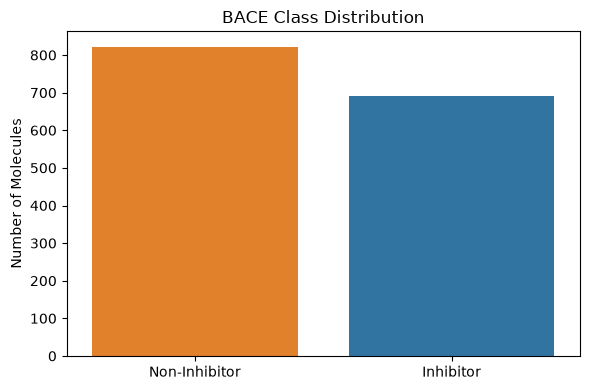

Class_Label
Non-Inhibitor    822
Inhibitor        691
Name: count, dtype: int64
Class_Label
Non-Inhibitor    0.543
Inhibitor        0.457
Name: proportion, dtype: float64


In [8]:
df["Class_Label"] = df["Class"].map(class_labels)

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Class_Label", hue="Class_Label",
              order=["Non-Inhibitor", "Inhibitor"], legend=False)
plt.title("BACE Class Distribution")
plt.xlabel("")
plt.ylabel("Number of Molecules")
plt.tight_layout()
plt.show()

print(df["Class_Label"].value_counts())
print(df["Class_Label"].value_counts(normalize=True).round(3))

In [9]:
datum = dataset[0]

print("Node features:", datum.x.shape)
print("Edges:", datum.edge_index.shape)
print("Label:", datum.y)
print("Number of nodes:", datum.num_nodes)
print("Number of edges:", datum.edge_index.shape[1])

Node features: torch.Size([32, 9])
Edges: torch.Size([2, 70])
Label: tensor([[1.]])
Number of nodes: 32
Number of edges: 70


## Plots

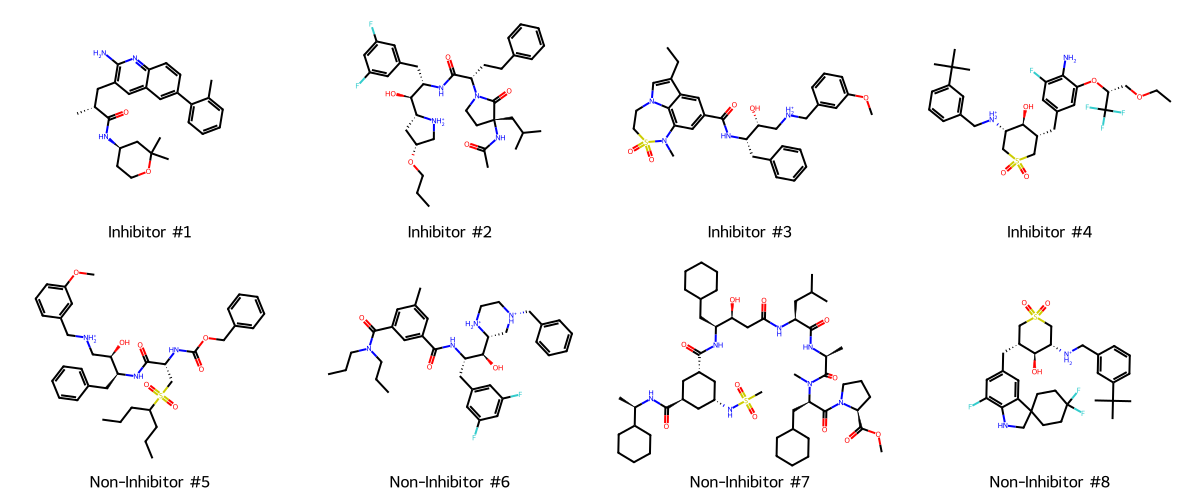

In [10]:
# Select the first 4 molecules from each class (not random)
inhibitors = df[df["Class"] == 1].head(4)
non_inhibitors = df[df["Class"] == 0].head(4)

selected = pd.concat([inhibitors, non_inhibitors])

# Convert SMILES to RDKit molecules
mols = [Chem.MolFromSmiles(s) for s in selected["mol"]]

# Labels for each molecule
legends = [
    f"{'Inhibitor' if label == 1 else 'Non-Inhibitor'} #{i + 1}"
    for i, label in enumerate(selected["Class"])
]

# Plot molecular structures
img = Draw.MolsToGridImage(
    mols,
    molsPerRow=4,
    subImgSize=(300, 250),
    legends=legends
)

display(img)

## Missing values

In [11]:
# Missing values
print("Missing values per column:")
print(df.isna().sum().sort_values(ascending=False))

# Exact duplicate rows
print("\nExact duplicate rows:", df.duplicated().sum())

# Duplicate molecular SMILES
smiles_col = "mol"  # Change if your SMILES column has a different name
print("Duplicate SMILES:", df[smiles_col].duplicated().sum())

# Target consistency among duplicate SMILES
duplicates = df[df[smiles_col].duplicated(keep=False)]
print(duplicates.sort_values(smiles_col)[[smiles_col, "Class"]].head(20))

Missing values per column:
mol                0
CID                0
Class              0
Model              0
pIC50              0
                  ..
PEOE12 (PEOE12)    0
PEOE13 (PEOE13)    0
PEOE14 (PEOE14)    0
canvasUID          0
Class_Label        0
Length: 596, dtype: int64

Exact duplicate rows: 0
Duplicate SMILES: 0
Empty DataFrame
Columns: [mol, Class]
Index: []


## Compare measured properties by class

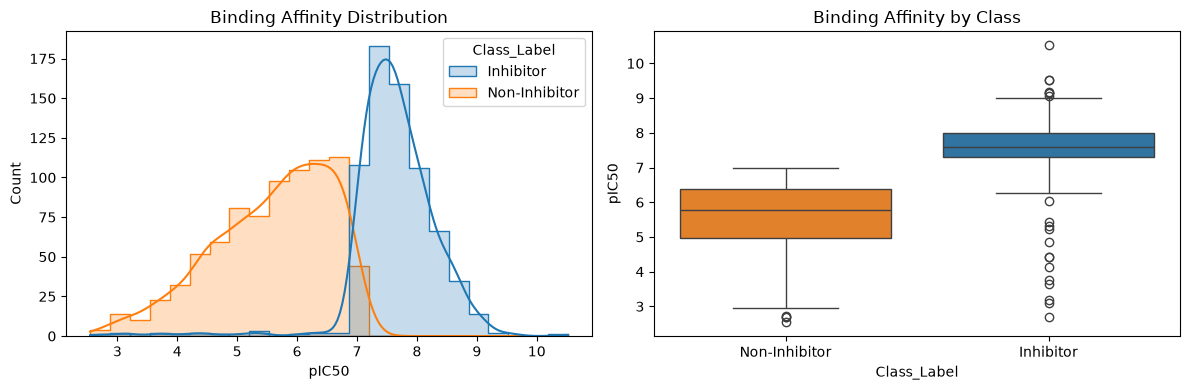

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    data=df, x="pIC50", hue="Class_Label",
    kde=True, element="step", ax=ax[0]
)
ax[0].set_title("Binding Affinity Distribution")

sns.boxplot(
    data=df, x="Class_Label", y="pIC50",
    hue="Class_Label",
    order=["Non-Inhibitor", "Inhibitor"],
    legend=False, ax=ax[1]
)
ax[1].set_title("Binding Affinity by Class")

plt.tight_layout()
plt.show()

## Molecular size and physicochemical properties

Class_Label     Inhibitor  Non-Inhibitor
MolWt              516.43         448.77
HeavyAtoms          36.77          31.83
LogP                 3.16           3.10
TPSA               102.80          88.79
HBD                  2.61           2.29
HBA                  5.05           4.40
RotatableBonds       8.57           6.93
Rings                3.92           3.66


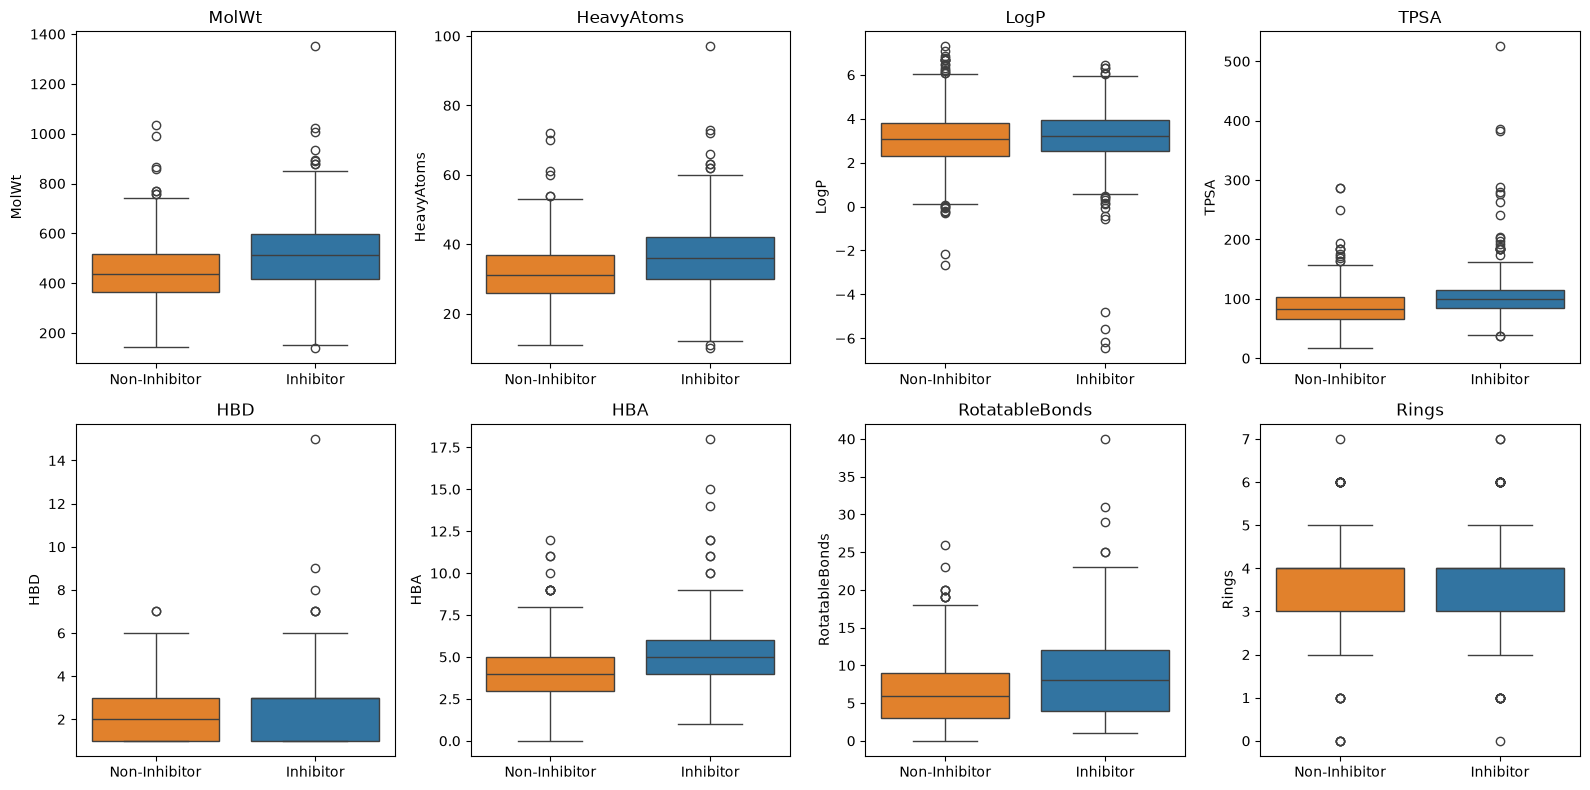

In [13]:
smiles_col = "mol"

def calculate_descriptors(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    return {
        "MolWt": Descriptors.MolWt(mol),
        "HeavyAtoms": mol.GetNumHeavyAtoms(),
        "LogP": Descriptors.MolLogP(mol),
        "TPSA": rdMolDescriptors.CalcTPSA(mol),
        "HBD": Lipinski.NumHDonors(mol),
        "HBA": Lipinski.NumHAcceptors(mol),
        "RotatableBonds": Lipinski.NumRotatableBonds(mol),
        "Rings": rdMolDescriptors.CalcNumRings(mol),
    }

descriptor_df = pd.DataFrame(
    df[smiles_col].apply(calculate_descriptors).tolist(),
    index=df.index
)

eda_df = pd.concat(
    [df[["Class_Label"]], descriptor_df],
    axis=1
)

print(eda_df.groupby("Class_Label").mean(numeric_only=True).T.round(2))

properties = [
    "MolWt", "HeavyAtoms", "LogP", "TPSA",
    "HBD", "HBA", "RotatableBonds", "Rings"
]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for prop, ax in zip(properties, axes.flat):
    sns.boxplot(
        data=eda_df,
        x="Class_Label",
        y=prop,
        hue="Class_Label",
        order=["Non-Inhibitor", "Inhibitor"],
        legend=False,
        ax=ax
    )
    ax.set_title(prop)
    ax.set_xlabel("")

plt.tight_layout()
plt.show()

## Molecular Graph structure

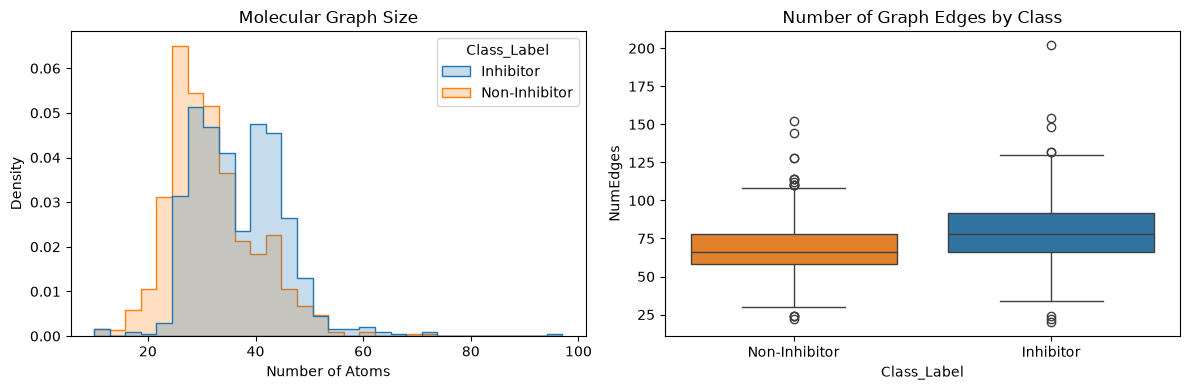

In [14]:
graph_stats = pd.DataFrame({
    "Class": [int(data.y.view(-1)[0]) for data in dataset],
    "NumNodes": [data.num_nodes for data in dataset],
    "NumEdges": [data.edge_index.size(1) for data in dataset],
})

graph_stats["Class_Label"] = graph_stats["Class"].map(class_labels)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    data=graph_stats, x="NumNodes",
    hue="Class_Label", bins=30,
    element="step", stat="density",
    common_norm=False, ax=axes[0]
)
axes[0].set_title("Molecular Graph Size")
axes[0].set_xlabel("Number of Atoms")

sns.boxplot(
    data=graph_stats, x="Class_Label",
    y="NumEdges", hue="Class_Label",
    order=["Non-Inhibitor", "Inhibitor"],
    legend=False, ax=axes[1]
)
axes[1].set_title("Number of Graph Edges by Class")

plt.tight_layout()
plt.show()

## Chemical diversity and structural similarity

In [15]:
# Preserve original DataFrame indices
results = []
fingerprints = []

fp_generator = rdFingerprintGenerator.GetMorganGenerator(
                    radius=2,
                    fpSize=2048
                )

for idx, smiles in df[smiles_col].items():
    mol = None
    status = "valid"
    reason = ""

    # 1. Check for missing values
    if pd.isna(smiles):
        status = "missing"
        reason = "Missing SMILES"

    # 2. Check input type
    elif not isinstance(smiles, str):
        status = "invalid_type"
        reason = f"Expected string, got {type(smiles).__name__}"

    # 3. Check for empty strings
    elif not smiles.strip():
        status = "empty"
        reason = "Empty SMILES string"

    else:
        try:
            # Parse and sanitize the molecular structure
            mol = Chem.MolFromSmiles(smiles.strip(), sanitize=True)

            if mol is None:
                status = "parse_failed"
                reason = "RDKit could not parse or sanitize SMILES"

        except Exception as exc:
            status = "parse_error"
            reason = str(exc)

    results.append({
        "original_index": idx,
        "smiles": smiles,
        "mol": mol,
        "status": status,
        "reason": reason
    })

# Create a validation report
validation_df = pd.DataFrame(results).set_index("original_index")

valid_mask = validation_df["mol"].notna()

valid_df = df.loc[valid_mask.to_numpy()].copy()
valid_mols = validation_df.loc[valid_mask, "mol"].tolist()
fingerprints = [
    fp_generator.GetFingerprint(mol)
    for mol in valid_mols
]

print("Total compounds:", len(df))
print("Successfully parsed:", len(valid_mols))
print("Failed or missing:", (~valid_mask).sum())

print("\nValidation status:")
print(validation_df["status"].value_counts(dropna=False))

# Inspect problematic entries
problems = validation_df.loc[~valid_mask, ["smiles", "status", "reason"]]
if not problems.empty:
    display(problems.head(20))

Total compounds: 1513
Successfully parsed: 1513
Failed or missing: 0

Validation status:
status
valid    1513
Name: count, dtype: int64


The Tanimoto coefficient measures the overlap between two molecular fingerprints:

1.0: identical fingerprints.

0.0: no shared fingerprint bits.

Higher values generally indicate greater structural similarity.

Non-Inhibitor vs Non-Inhibitor: n=337,431, mean=0.159, median=0.131, 90th percentile=0.256
Inhibitor vs Inhibitor: n=238,395, mean=0.185, median=0.142, 90th percentile=0.330
Inhibitor vs Non-Inhibitor: n=568,002, mean=0.161, median=0.135, 90th percentile=0.272


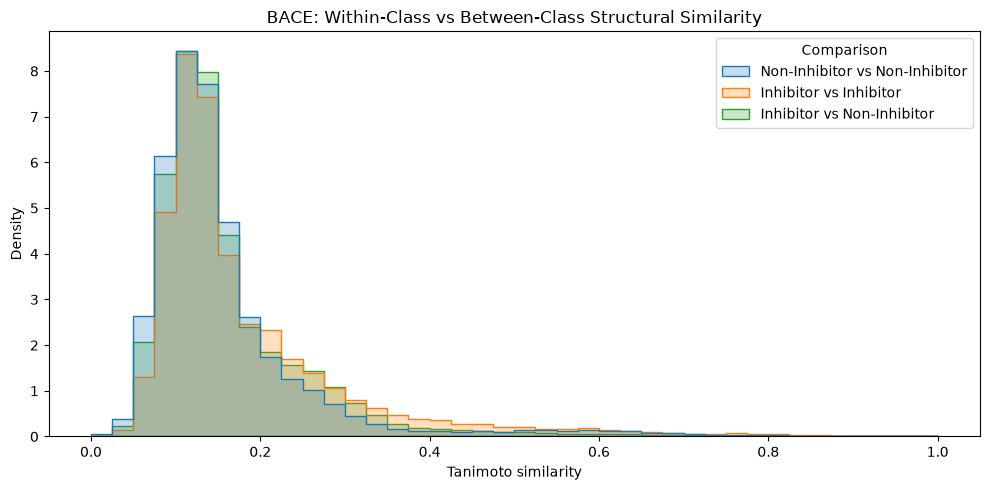

In [16]:
# Binary labels: 0 = Non-Inhibitor, 1 = Inhibitor
labels = valid_df["Class"].to_numpy().astype(int)

def pairwise_tanimoto(fps_a, fps_b, same_group=False):
    """Calculate pairwise Tanimoto similarities without self-pairs."""
    similarities = []

    for i, fp in enumerate(fps_a):
        start = i + 1 if same_group else 0
        similarities.extend(
            DataStructs.BulkTanimotoSimilarity(fp, fps_b[start:])
        )

    return np.asarray(similarities)


fps_0 = [fp for fp, y in zip(fingerprints, labels) if y == 0]
fps_1 = [fp for fp, y in zip(fingerprints, labels) if y == 1]

similarity_groups = {
    "Non-Inhibitor vs Non-Inhibitor":
        pairwise_tanimoto(fps_0, fps_0, same_group=True),
    "Inhibitor vs Inhibitor":
        pairwise_tanimoto(fps_1, fps_1, same_group=True),
    "Inhibitor vs Non-Inhibitor":
        pairwise_tanimoto(fps_1, fps_0),
}

# Summary statistics
for name, sims in similarity_groups.items():
    print(
        f"{name}: n={len(sims):,}, "
        f"mean={sims.mean():.3f}, "
        f"median={np.median(sims):.3f}, "
        f"90th percentile={np.quantile(sims, 0.90):.3f}"
    )


similarity_df = pd.DataFrame([
    {"Comparison": name, "Tanimoto similarity": value}
    for name, values in similarity_groups.items()
    for value in values
])

plt.figure(figsize=(10, 5))
sns.histplot(
    data=similarity_df,
    x="Tanimoto similarity",
    hue="Comparison",
    bins=40,
    element="step",
    stat="density",
    common_norm=False
)
plt.title("BACE: Within-Class vs Between-Class Structural Similarity")
plt.tight_layout()
plt.show()

Your results suggest that BACE inhibitors are, on average, somewhat more structurally similar to one another than non-inhibitors are to one another, but the difference is modest. The between-class similarities are close to the non-inhibitor within-class similarities, and you report substantial overlap between all three distributions.

This means Morgan fingerprints alone do not show a strong separation between inhibitors and non-inhibitors at the level of pairwise structural similarity.

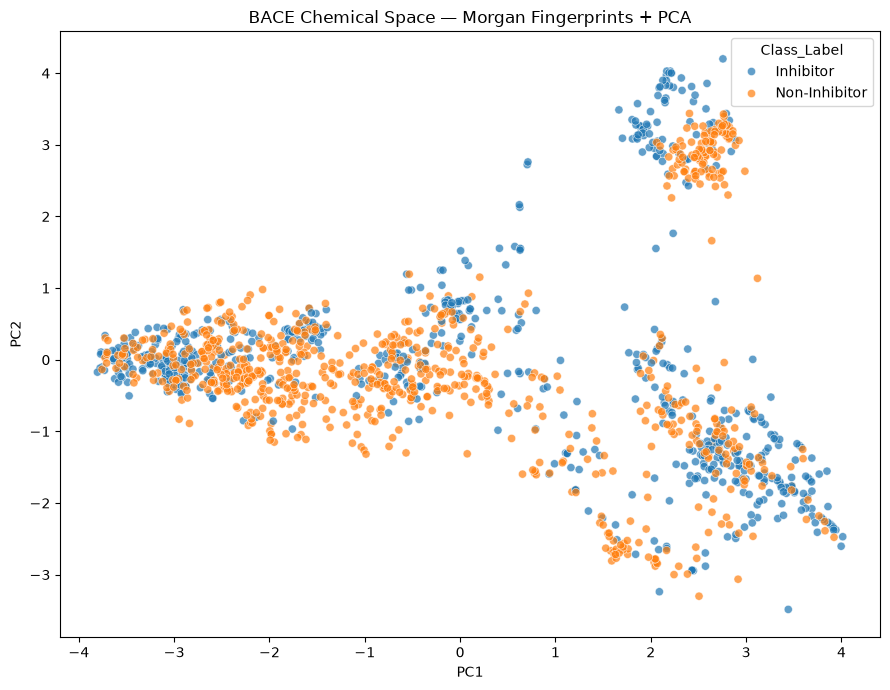

Explained variance ratio: [0.12157706 0.04942235]
Total variance explained by PC1 and PC2: 0.171


In [17]:
from sklearn.decomposition import PCA

# Convert RDKit fingerprints to a binary NumPy matrix
X = np.zeros((len(fingerprints), 2048), dtype=np.uint8)

for i, fp in enumerate(fingerprints):
    DataStructs.ConvertToNumpyArray(fp, X[i])

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plot_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Class": labels
})
plot_df["Class_Label"] = plot_df["Class"].map({
    0: "Non-Inhibitor",
    1: "Inhibitor"
})

plt.figure(figsize=(9, 7))
sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="Class_Label",
    alpha=0.7,
    s=35
)
plt.title("BACE Chemical Space — Morgan Fingerprints + PCA")
plt.tight_layout()
plt.show()

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance explained by PC1 and PC2:",
      round(pca.explained_variance_ratio_.sum(), 3))

## Check structural similarity across train/test splits

Training molecules: 1210
Test molecules: 303
Mean max similarity: 0.788
Median max similarity: 0.800
Test molecules with train similarity >= 0.5: 295/303 (97.4%)
Test molecules with train similarity >= 0.7: 260/303 (85.8%)
Test molecules with train similarity >= 0.9: 32/303 (10.6%)
Test molecules with train similarity >= 1.0: 10/303 (3.3%)


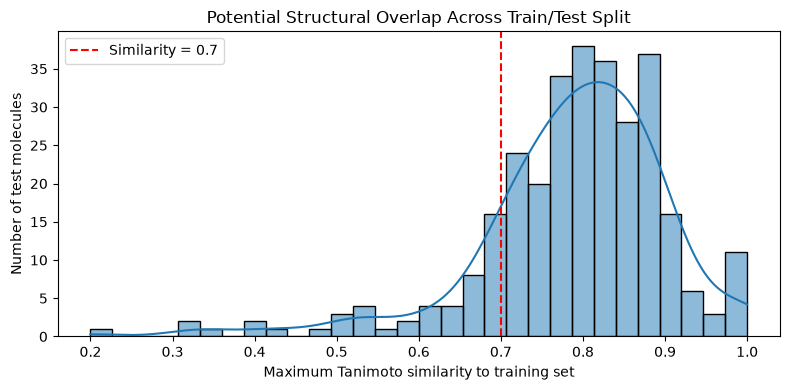

In [18]:
from sklearn.model_selection import train_test_split

# Split molecule indices, preserving class proportions
indices = np.arange(len(fingerprints))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

train_fps = [fingerprints[i] for i in train_idx]
test_fps = [fingerprints[i] for i in test_idx]

# Maximum similarity to any training molecule for each test molecule
max_train_similarity = []

for fp in test_fps:
    sims = DataStructs.BulkTanimotoSimilarity(fp, train_fps)
    max_train_similarity.append(max(sims) if sims else 0.0)

max_train_similarity = np.array(max_train_similarity)

print(f"Training molecules: {len(train_idx)}")
print(f"Test molecules: {len(test_idx)}")
print(f"Mean max similarity: {max_train_similarity.mean():.3f}")
print(f"Median max similarity: {np.median(max_train_similarity):.3f}")

for threshold in [0.5, 0.7, 0.9, 1.0]:
    count = (max_train_similarity >= threshold).sum()
    print(
        f"Test molecules with train similarity >= {threshold:.1f}: "
        f"{count}/{len(test_idx)} "
        f"({count / len(test_idx):.1%})"
    )

plt.figure(figsize=(8, 4))

sns.histplot(max_train_similarity, bins=30, kde=True)

plt.axvline(
    0.7,
    color="red",
    linestyle="--",
    label="Similarity = 0.7"
)

plt.xlabel("Maximum Tanimoto similarity to training set")
plt.ylabel("Number of test molecules")
plt.title("Potential Structural Overlap Across Train/Test Split")
plt.legend()
plt.tight_layout()
plt.show()

In [19]:
rows = []

for test_position, fp in zip(test_idx, test_fps):
    sims = np.array(
        DataStructs.BulkTanimotoSimilarity(fp, train_fps)
    )

    nearest_local_idx = int(np.argmax(sims))
    nearest_train_idx = train_idx[nearest_local_idx]

    rows.append({
        "Test_Index": valid_df.index[test_position],
        "Test_Class": labels[test_position],
        "Train_Index": valid_df.index[nearest_train_idx],
        "Train_Class": labels[nearest_train_idx],
        "Max_Tanimoto": sims[nearest_local_idx],
    })

nearest_neighbors = pd.DataFrame(rows)

print(
    nearest_neighbors
    .sort_values("Max_Tanimoto", ascending=False)
    .head(20)
    .to_string(index=False)
)

 Test_Index  Test_Class  Train_Index  Train_Class  Max_Tanimoto
          3           1          581            1      1.000000
         60           1          126            0      1.000000
       1078           0         1328            0      1.000000
        181           0         1488            0      1.000000
        684           1          959            0      1.000000
         50           1         1130            0      1.000000
         46           1           63            1      1.000000
        932           0         1412            0      1.000000
        796           0         1341            0      1.000000
         39           1           68            1      1.000000
         72           1          893            0      0.982759
        361           1          277            1      0.964706
       1151           0         1007            0      0.961538
          9           1          516            1      0.958904
        769           1          554    

In [20]:
from collections import defaultdict
from rdkit.Chem.Scaffolds import MurckoScaffold
import numpy as np
import pandas as pd

# Group molecule indices by Bemis–Murcko scaffold
scaffold_groups = defaultdict(list)

for i, mol in enumerate(valid_mols):
    scaffold = MurckoScaffold.MurckoScaffoldSmiles(mol=mol)
    # Empty scaffolds (e.g. acyclic molecules) share the empty scaffold.
    scaffold_groups[scaffold].append(i)

print("Unique scaffolds:", len(scaffold_groups))
print("Total molecules:", len(valid_mols))

# Deterministic allocation: largest scaffold groups first.
# Break ties deterministically using the scaffold string.
groups = sorted(
    scaffold_groups.items(),
    key=lambda item: (-len(item[1]), item[0])
)

target_test_size = round(0.20 * len(valid_mols))
train_idx_scaffold = []
test_idx_scaffold = []

for scaffold, members in groups:
    # Put the entire scaffold group in whichever partition best
    # approaches the target test size.
    if len(test_idx_scaffold) < target_test_size:
        if (
            abs(len(test_idx_scaffold) + len(members) - target_test_size)
            <= abs(len(test_idx_scaffold) - target_test_size)
        ):
            test_idx_scaffold.extend(members)
        else:
            train_idx_scaffold.extend(members)
    else:
        train_idx_scaffold.extend(members)

# Handle the edge case where the test partition is empty.
if not test_idx_scaffold:
    largest_scaffold, members = groups[0]
    test_idx_scaffold.extend(members)
    train_idx_scaffold = [
        i for i in range(len(valid_mols))
        if i not in set(test_idx_scaffold)
    ]

train_idx_scaffold = np.array(sorted(train_idx_scaffold))
test_idx_scaffold = np.array(sorted(test_idx_scaffold))

print(f"Train: {len(train_idx_scaffold)} "
      f"({len(train_idx_scaffold) / len(valid_mols):.1%})")
print(f"Test:  {len(test_idx_scaffold)} "
      f"({len(test_idx_scaffold) / len(valid_mols):.1%})")

Unique scaffolds: 671
Total molecules: 1513
Train: 1207 (79.8%)
Test:  306 (20.2%)


In [21]:
scaffold_by_idx = {
    i: scaffold
    for scaffold, members in scaffold_groups.items()
    for i in members
}

train_scaffolds = {
    scaffold_by_idx[i] for i in train_idx_scaffold
}
test_scaffolds = {
    scaffold_by_idx[i] for i in test_idx_scaffold
}

overlap = train_scaffolds & test_scaffolds

print("Scaffolds shared between train and test:", len(overlap))
assert len(overlap) == 0

Scaffolds shared between train and test: 0


In [22]:
train_fps_scaffold = [
    fingerprints[i] for i in train_idx_scaffold
]
test_fps_scaffold = [
    fingerprints[i] for i in test_idx_scaffold
]

nearest_scaffold = []

for i, fp in zip(test_idx_scaffold, test_fps_scaffold):
    sims = np.asarray(
        DataStructs.BulkTanimotoSimilarity(fp, train_fps_scaffold)
    )
    j = int(np.argmax(sims))
    nearest_scaffold.append({
        "Test_Index": valid_df.index[i],
        "Test_Class": labels[i],
        "Train_Index": valid_df.index[train_idx_scaffold[j]],
        "Train_Class": labels[train_idx_scaffold[j]],
        "Max_Tanimoto": sims[j],
    })

scaffold_neighbors = pd.DataFrame(nearest_scaffold)

print(
    scaffold_neighbors
    .sort_values("Max_Tanimoto", ascending=False)
    .head(20)
    .to_string(index=False)
)

print("\nSimilarity summary:")
print(scaffold_neighbors["Max_Tanimoto"].describe())

print("\nFraction above similarity thresholds:")
for threshold in [0.5, 0.7, 0.9, 1.0]:
    fraction = (
        scaffold_neighbors["Max_Tanimoto"] >= threshold
    ).mean()
    print(f">= {threshold:.1f}: {fraction:.1%}")

 Test_Index  Test_Class  Train_Index  Train_Class  Max_Tanimoto
         72           1          893            0      0.982759
       1184           0          949            0      0.915254
        836           0          420            1      0.892857
        510           1          841            0      0.870968
        653           1          841            0      0.870968
        682           1          352            1      0.864198
         15           1          366            1      0.863014
        458           1          366            1      0.863014
        158           0          366            1      0.863014
       1356           0          159            0      0.862745
        252           1          705            1      0.862500
        681           1          352            1      0.857143
        867           0          352            1      0.857143
        954           0          841            0      0.857143
        673           1          705    

In [23]:
def summarize_similarity(similarities, split_name):
    similarities = np.asarray(similarities)

    return {
        "Split": split_name,
        "N_test": len(similarities),
        "Mean": similarities.mean(),
        "Median": np.median(similarities),
        "90th percentile": np.quantile(similarities, 0.90),
        "Fraction >= 0.7": np.mean(similarities >= 0.7),
        "Fraction >= 0.9": np.mean(similarities >= 0.9),
        "Fraction = 1.0": np.mean(np.isclose(similarities, 1.0)),
    }

comparison = pd.DataFrame([
    summarize_similarity(max_train_similarity, "Random"),
    summarize_similarity(
        scaffold_neighbors["Max_Tanimoto"].to_numpy(),
        "Scaffold"
    )
]).set_index("Split")

print(comparison.round(3))

          N_test   Mean  Median  90th percentile  Fraction >= 0.7  \
Split                                                               
Random       303  0.788    0.80            0.904            0.858   
Scaffold     306  0.733    0.74            0.834            0.696   

          Fraction >= 0.9  Fraction = 1.0  
Split                                      
Random              0.106           0.033  
Scaffold            0.007           0.000  


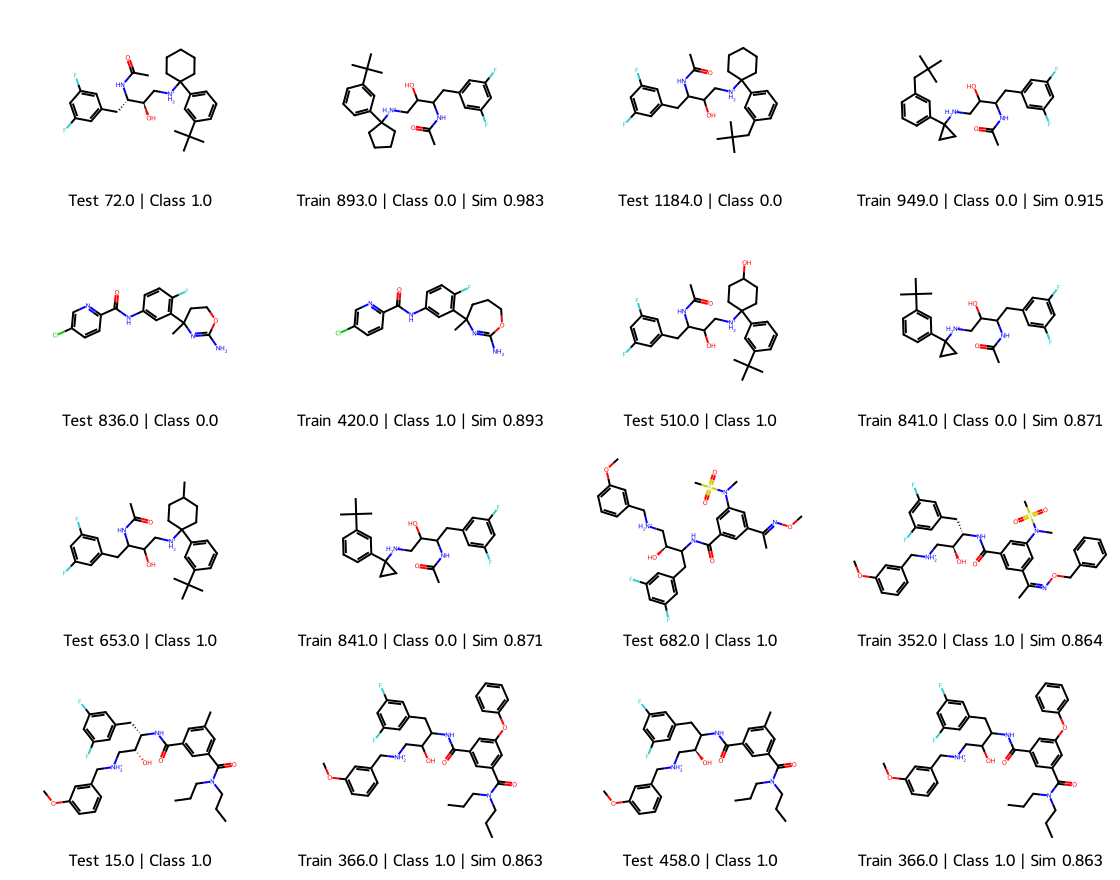

In [24]:
top_pairs = (
    scaffold_neighbors
    .sort_values("Max_Tanimoto", ascending=False)
    .head(8)
)

mols_to_draw = []
legends = []

for _, row in top_pairs.iterrows():
    test_idx = valid_df.index.get_loc(row["Test_Index"])
    train_idx = valid_df.index.get_loc(row["Train_Index"])

    test_mol = valid_mols[test_idx]
    train_mol = valid_mols[train_idx]

    mols_to_draw.extend([test_mol, train_mol])

    legends.extend([
        f"Test {row['Test_Index']} | Class {row['Test_Class']}",
        f"Train {row['Train_Index']} | Class {row['Train_Class']} | "
        f"Sim {row['Max_Tanimoto']:.3f}"
    ])

display(
    Draw.MolsToGridImage(
        mols_to_draw,
        molsPerRow=4,
        subImgSize=(280, 220),
        legends=legends
    )
)

In [25]:
fp_chiral = rdFingerprintGenerator.GetMorganGenerator(
    radius=2, fpSize=2048, includeChirality=True
)

def canonical_smiles(mol, isomeric=True):
    """Return canonical SMILES, optionally preserving stereochemistry."""
    return Chem.MolToSmiles(
        mol, canonical=True, isomericSmiles=isomeric
    )

rows = []

for _, row in top_pairs.iterrows():
    # Convert original DataFrame indices to positions in the filtered molecule list.
    test_i = valid_df.index.get_loc(row["Test_Index"])
    train_i = valid_df.index.get_loc(row["Train_Index"])

    test_mol = valid_mols[test_i]
    train_mol = valid_mols[train_i]

    test_chiral = fp_chiral.GetFingerprint(test_mol)
    train_chiral = fp_chiral.GetFingerprint(train_mol)

    test_iso = canonical_smiles(test_mol, True)
    train_iso = canonical_smiles(train_mol, True)

    test_noniso = canonical_smiles(test_mol, False)
    train_noniso = canonical_smiles(train_mol, False)

    rows.append({
        "Test_Index": row["Test_Index"],
        "Train_Index": row["Train_Index"],
        # Reuse the non-chiral similarity already calculated upstream.
        "Original_Similarity": row["Max_Tanimoto"],
        "Same_Nonisomeric_SMILES": test_noniso == train_noniso,
        "Same_Isomeric_SMILES": test_iso == train_iso,
        "Chiral_Tanimoto": DataStructs.TanimotoSimilarity(
            test_chiral, train_chiral
        ),
        "Test_SMILES": test_iso,
        "Train_SMILES": train_iso,
    })

stereo_df = pd.DataFrame(rows)

print(stereo_df.to_string(index=False))

 Test_Index  Train_Index  Original_Similarity  Same_Nonisomeric_SMILES  Same_Isomeric_SMILES  Chiral_Tanimoto                                                                               Test_SMILES                                                                                         Train_SMILES
       72.0        893.0             0.982759                    False                 False         0.781250                 CC(=O)N[C@@H](Cc1cc(F)cc(F)c1)[C@H](O)C[NH2+]C1(c2cccc(C(C)(C)C)c2)CCCCC1                                      CC(=O)NC(Cc1cc(F)cc(F)c1)C(O)C[NH2+]C1(c2cccc(C(C)(C)C)c2)CCCC1
     1184.0        949.0             0.915254                    False                 False         0.915254                         CC(=O)NC(Cc1cc(F)cc(F)c1)C(O)C[NH2+]C1(c2cccc(CC(C)(C)C)c2)CCCCC1                                       CC(=O)NC(Cc1cc(F)cc(F)c1)C(O)C[NH2+]C1(c2cccc(CC(C)(C)C)c2)CC1
      836.0        420.0             0.892857                    False                 False     

In [26]:
print("Nearest-neighbor pairs:", len(stereo_df))

print(
    "Same connectivity:",
    stereo_df["Same_Nonisomeric_SMILES"].sum()
)

print(
    "Same connectivity, different stereochemical SMILES:",
    (
        stereo_df["Same_Nonisomeric_SMILES"]
        & ~stereo_df["Same_Isomeric_SMILES"]
    ).sum()
)

print(
    "Same exact isomeric SMILES:",
    stereo_df["Same_Isomeric_SMILES"].sum()
)

Nearest-neighbor pairs: 8
Same connectivity: 0
Same connectivity, different stereochemical SMILES: 0
Same exact isomeric SMILES: 0


## Quantify scaffold overlap between classes

In [27]:
scaffold_records = []

for i, mol in enumerate(valid_mols):
    scaffold = MurckoScaffold.MurckoScaffoldSmiles(mol=mol)

    scaffold_records.append({
        "index": valid_df.index[i],
        "scaffold": scaffold,
        "Class": int(labels[i]),
    })

scaffold_df = pd.DataFrame(scaffold_records)

# Number of molecules from each class per scaffold
scaffold_counts = pd.crosstab(
    scaffold_df["scaffold"],
    scaffold_df["Class"]
).rename(columns={0: "Non-Inhibitor", 1: "Inhibitor"})

scaffold_counts["Total"] = scaffold_counts.sum(axis=1)

shared_scaffolds = scaffold_counts[
    (scaffold_counts["Non-Inhibitor"] > 0)
    & (scaffold_counts["Inhibitor"] > 0)
]

print("Unique scaffolds:", len(scaffold_counts))
print("Scaffolds shared by both classes:", len(shared_scaffolds))
print(
    "Fraction of scaffolds shared:",
    round(len(shared_scaffolds) / len(scaffold_counts), 3)
)

print("\nMolecules belonging to shared scaffolds:")
print(
    scaffold_counts.loc[shared_scaffolds.index, ["Non-Inhibitor", "Inhibitor"]]
    .sum()
)

Unique scaffolds: 671
Scaffolds shared by both classes: 64
Fraction of scaffolds shared: 0.095

Molecules belonging to shared scaffolds:
Class
Non-Inhibitor    241
Inhibitor        353
dtype: int64


In [28]:
fps_0 = [fp for fp, y in zip(fingerprints, labels) if y == 0]
fps_1 = [fp for fp, y in zip(fingerprints, labels) if y == 1]

# For each molecule, calculate its mean similarity to each class
within_similarities = []
between_similarities = []

for fp, y in zip(fingerprints, labels):
    same_class_fps = fps_1 if y == 1 else fps_0
    other_class_fps = fps_0 if y == 1 else fps_1

    same_sims = np.asarray(
        DataStructs.BulkTanimotoSimilarity(fp, same_class_fps)
    )
    other_sims = np.asarray(
        DataStructs.BulkTanimotoSimilarity(fp, other_class_fps)
    )

    # Exclude the molecule itself from its own class
    same_sims = same_sims[same_sims < 1.0]

    if len(same_sims):
        within_similarities.append(same_sims.mean())
        between_similarities.append(other_sims.mean())

print("Mean within-class similarity:",
      np.mean(within_similarities))
print("Mean between-class similarity:",
      np.mean(between_similarities))
print("Mean difference:",
      np.mean(within_similarities) - np.mean(between_similarities))

Mean within-class similarity: 0.17078721806542244
Mean between-class similarity: 0.16091885761662872
Mean difference: 0.009868360448793717


In [29]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    f1_score
)

# Convert fingerprints to a binary feature matrix
X = np.zeros((len(fingerprints), 2048), dtype=np.uint8)

for i, fp in enumerate(fingerprints):
    DataStructs.ConvertToNumpyArray(fp, X[i])

# Use the scaffold split already created
X_train = X[train_idx_scaffold]
X_test = X[test_idx_scaffold]
y_train = labels[train_idx_scaffold]
y_test = labels[test_idx_scaffold]

clf = RandomForestClassifier(
    n_estimators=500,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

clf.fit(X_train, y_train)

y_prob = clf.predict_proba(X_test)[:, 1]
y_pred = clf.predict(X_test)

print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))
print("PR-AUC:", round(average_precision_score(y_test, y_prob), 3))
print("Balanced accuracy:", round(
    balanced_accuracy_score(y_test, y_pred), 3
))

ROC-AUC: 0.838
PR-AUC: 0.884
Balanced accuracy: 0.741


## Compare random and scaffold splits using the same model

In [30]:
X = np.zeros((len(fingerprints), 2048), dtype=np.uint8)

for i, fp in enumerate(fingerprints):
    DataStructs.ConvertToNumpyArray(fp, X[i])

print("X shape:", X.shape)
print("Labels shape:", labels.shape)

X shape: (1513, 2048)
Labels shape: (1513,)


In [31]:
print("X type:", type(X))
print("X shape:", np.asarray(X).shape)
print("X ndim:", np.asarray(X).ndim)

print("First fingerprint type:", type(fingerprints[0]))
print("Number of fingerprints:", len(fingerprints))
print("Labels shape:", np.asarray(labels).shape)

X type: <class 'numpy.ndarray'>
X shape: (1513, 2048)
X ndim: 2
First fingerprint type: <class 'rdkit.DataStructs.cDataStructs.ExplicitBitVect'>
Number of fingerprints: 1513
Labels shape: (1513,)


In [32]:
X_fp = np.zeros((len(fingerprints), 2048), dtype=np.float32)

for i, fp in enumerate(fingerprints):
    DataStructs.ConvertToNumpyArray(fp, X_fp[i])

# 2. Build labels aligned with the fingerprints
y = valid_df["Class"].to_numpy(dtype=int)

print("Feature matrix:", X_fp.shape)
print("Labels:", y.shape)

assert X_fp.ndim == 2
assert len(X_fp) == len(y)

Feature matrix: (1513, 2048)
Labels: (1513,)


In [33]:
all_idx = np.arange(len(y))

random_train, random_test = train_test_split(
    all_idx,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

In [34]:
def evaluate_split(X, y, train_idx, test_idx):
    model = RandomForestClassifier(
        n_estimators=500,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X[train_idx], y[train_idx])

    probabilities = model.predict_proba(X[test_idx])[:, 1]
    predictions = model.predict(X[test_idx])

    return {
        "ROC-AUC": roc_auc_score(y[test_idx], probabilities),
        "PR-AUC": average_precision_score(y[test_idx], probabilities),
        "Balanced accuracy": balanced_accuracy_score(
            y[test_idx], predictions
        )
    }


In [35]:
results = pd.DataFrame({
    "Random split": evaluate_split(
        X_fp, y, random_train, random_test
    ),
    "Scaffold split": evaluate_split(
        X_fp, y, train_idx_scaffold, test_idx_scaffold
    ),
}).T

print(results.round(3))

                ROC-AUC  PR-AUC  Balanced accuracy
Random split      0.884   0.858              0.789
Scaffold split    0.838   0.884              0.741


RANDOM SPLIT
               precision    recall  f1-score   support

Non-Inhibitor      0.818     0.788     0.802       165
    Inhibitor      0.757     0.790     0.773       138

     accuracy                          0.789       303
    macro avg      0.787     0.789     0.788       303
 weighted avg      0.790     0.789     0.789       303

Confusion matrix:
[[130  35]
 [ 29 109]]


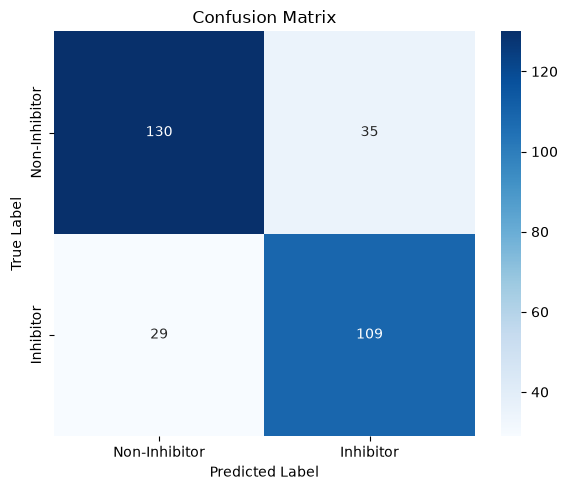


SCAFFOLD SPLIT
               precision    recall  f1-score   support

Non-Inhibitor      0.722     0.645     0.681       121
    Inhibitor      0.783     0.838     0.809       185

     accuracy                          0.761       306
    macro avg      0.753     0.741     0.745       306
 weighted avg      0.759     0.761     0.759       306

Confusion matrix:
[[ 78  43]
 [ 30 155]]


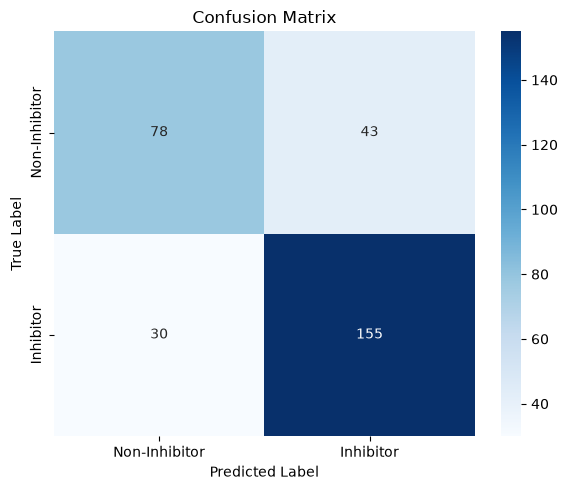

In [36]:
from sklearn.metrics import confusion_matrix, classification_report

def detailed_evaluation(X_features, y_labels, train_ids, test_ids):
    model = RandomForestClassifier(
        n_estimators=500,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    )
    model.fit(X_features[train_ids], y_labels[train_ids])

    predictions = model.predict(X_features[test_ids])

    print(classification_report(
        y_labels[test_ids],
        predictions,
        target_names=["Non-Inhibitor", "Inhibitor"],
        digits=3,
        zero_division=0,
    ))

    print("Confusion matrix:")
    print(confusion_matrix(y_labels[test_ids], predictions))
    
    plt.figure(figsize=(6, 5))
    cm = confusion_matrix(y_labels[test_ids], predictions)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Non-Inhibitor", "Inhibitor"],
        yticklabels=["Non-Inhibitor", "Inhibitor"],
    )
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.title("Confusion Matrix")
    plt.tight_layout()
    plt.show()


print("RANDOM SPLIT")
detailed_evaluation(X_fp, y, random_train, random_test)

print("\nSCAFFOLD SPLIT")
detailed_evaluation(
    X_fp, y, train_idx_scaffold, test_idx_scaffold
)

c:\Users\user\OneDrive\Desktop\GitHub\bace-alzheimers-classification\env\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\Users\user\OneDrive\Desktop\GitHub\bace-alzheimers-classification\env\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\Users\user\OneDrive\Desktop\GitHub\bace-alzheimers-classification\env\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\Users\user\OneDrive\Desktop\GitHub\bace-alzheimers-classification\e

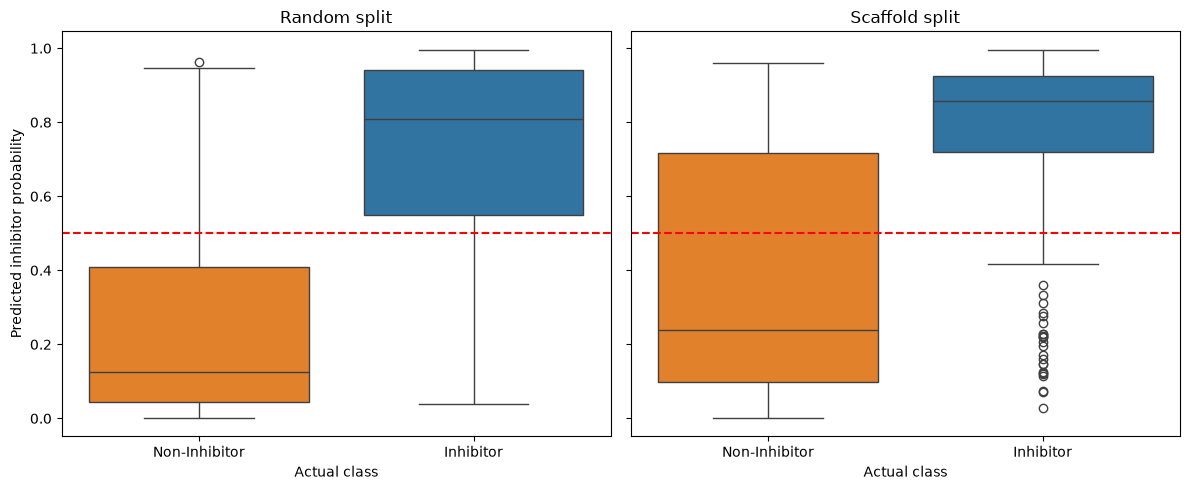

In [37]:
def get_predictions(X, y, train_idx, test_idx, split_name):
    model = RandomForestClassifier(
        n_estimators=500,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    )
    model.fit(X[train_idx], y[train_idx])

    probabilities = model.predict_proba(X[test_idx])[:, 1]

    return pd.DataFrame({
        "Split": split_name,
        "Actual class": [
            "Inhibitor" if label == 1 else "Non-Inhibitor"
            for label in y[test_idx]
        ],
        "Predicted inhibitor probability": probabilities,
    })

prob_df = pd.concat([
    get_predictions(X_fp, y, random_train, random_test, "Random"),
    get_predictions(
        X_fp, y, train_idx_scaffold, test_idx_scaffold, "Scaffold"
    ),
], ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, split_name in zip(axes, ["Random", "Scaffold"]):
    subset = prob_df[prob_df["Split"] == split_name]

    sns.boxplot(
        data=subset,
        x="Actual class",
        y="Predicted inhibitor probability",
        hue="Actual class",
        order=["Non-Inhibitor", "Inhibitor"],
        legend=False,
        ax=ax,
    )

    ax.axhline(0.5, color="red", linestyle="--")
    ax.set_title(f"{split_name} split")
    ax.set_xlabel("Actual class")

plt.tight_layout()
plt.show()

In [38]:

# Fit on the scaffold training set
model = RandomForestClassifier(
    n_estimators=500,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)

model.fit(X_fp[train_idx_scaffold], y[train_idx_scaffold])

# Predict on the scaffold test set
test_prob = model.predict_proba(X_fp[test_idx_scaffold])[:, 1]
test_pred = (test_prob >= 0.5).astype(int)

# Find false positives: actual non-inhibitors predicted as inhibitors
fp_mask = (y[test_idx_scaffold] == 0) & (test_pred == 1)
fp_positions = test_idx_scaffold[fp_mask]
fp_probabilities = test_prob[fp_mask]

print("False positives:", len(fp_positions))

False positives: 43


In [39]:
fp_records = []

train_fps = [fingerprints[i] for i in train_idx_scaffold]

for i, probability in zip(fp_positions, fp_probabilities):
    mol = valid_mols[i]
    fp = fingerprints[i]

    scaffold = MurckoScaffold.MurckoScaffoldSmiles(mol=mol)

    # Find nearest training molecule by Tanimoto similarity
    similarities = np.asarray(
        DataStructs.BulkTanimotoSimilarity(fp, train_fps)
    )
    nearest_local = int(np.argmax(similarities))
    nearest_i = train_idx_scaffold[nearest_local]

    fp_records.append({
        "Index": valid_df.index[i],
        "Scaffold": scaffold,
        "Predicted_Probability": probability,
        "Nearest_Train_Index": valid_df.index[nearest_i],
        "Nearest_Train_Class": int(y[nearest_i]),
        "Nearest_Tanimoto": similarities[nearest_local],
        "SMILES": Chem.MolToSmiles(mol, isomericSmiles=True),
        "Nearest_Train_SMILES": Chem.MolToSmiles(
            valid_mols[nearest_i], isomericSmiles=True
        ),
    })

false_positives = (
    pd.DataFrame(fp_records)
    .sort_values("Predicted_Probability", ascending=False)
)

print(false_positives[
    [
        "Index",
        "Predicted_Probability",
        "Nearest_Train_Index",
        "Nearest_Train_Class",
        "Nearest_Tanimoto",
        "Scaffold",
    ]
].to_string(index=False))

 Index  Predicted_Probability  Nearest_Train_Index  Nearest_Train_Class  Nearest_Tanimoto                                            Scaffold
   818               0.960000                  493                    1          0.820513         O=C(NC(CC[NH2+]Cc1ccccc1)Cc1ccccc1)c1ccccc1
   158               0.954000                  366                    1          0.863014         O=C(NC(CC[NH2+]Cc1ccccc1)Cc1ccccc1)c1ccccc1
   819               0.946000                  438                    1          0.828947         O=C(NC(CC[NH2+]Cc1ccccc1)Cc1ccccc1)c1ccccc1
   836               0.936667                  420                    1          0.892857                   O=C(Nc1cccc(C2CCOC=N2)c1)c1ccccn1
  1009               0.915167                  567                    1          0.698413             O=C1NC=NC1(c1ccccc1)c1cccc(-c2cccnc2)c1
  1026               0.889333                  548                    1          0.641791             O=C1NC=NC1(c1ccccc1)c1cccc(-c2cccnc2)c1
   812

In [40]:
test_scaffold_records = []

for i, probability, prediction in zip(
    test_idx_scaffold, test_prob, test_pred
):
    scaffold = MurckoScaffold.MurckoScaffoldSmiles(
        mol=valid_mols[i]
    )

    test_scaffold_records.append({
        "Index": valid_df.index[i],
        "Scaffold": scaffold,
        "Actual": int(y[i]),
        "Predicted": int(prediction),
        "Probability": probability,
    })

test_scaffolds_df = pd.DataFrame(test_scaffold_records)

scaffold_errors = (
    test_scaffolds_df
    .groupby("Scaffold")
    .agg(
        Test_Molecules=("Index", "size"),
        NonInhibitors=("Actual", lambda s: (s == 0).sum()),
        False_Positives=(
            "Actual",
            lambda s: (
                (s == 0)
                & (
                    test_scaffolds_df.loc[s.index, "Predicted"] == 1
                )
            ).sum(),
        ),
        Mean_Inhibitor_Probability=("Probability", "mean"),
    )
    .sort_values("False_Positives", ascending=False)
)

scaffold_errors = scaffold_errors[
    scaffold_errors["False_Positives"] > 0
]

scaffold_errors["FP_Rate_among_NonInhibitors"] = (
    scaffold_errors["False_Positives"]
    / scaffold_errors["NonInhibitors"].replace(0, np.nan)
)

print(scaffold_errors.head(20).round(3))

                                                    Test_Molecules  \
Scaffold                                                             
O=C(NC(CC[NH2+]Cc1ccccc1)Cc1ccccc1)c1c[nH]c2ccc...              16   
O=C1NC=NC1(c1ccccc1)c1ccccc1                                    55   
O=C(NC(CC[NH2+]Cc1ccccc1)Cc1ccccc1)c1ccccc1                     26   
O=C(Nc1cccc(C2CCOC=N2)c1)c1ccccn1                               26   
O=C1NC=NC1(c1ccccc1)c1cccc(-c2cccnc2)c1                         22   
O=S1(=O)CC(Cc2ccccc2)CC([NH2+]Cc2ccccc2)C1                      53   
c1ccc(CCCC[NH2+]C2CC3(CCC3)Oc3ncccc32)cc1                       31   

                                                    NonInhibitors  \
Scaffold                                                            
O=C(NC(CC[NH2+]Cc1ccccc1)Cc1ccccc1)c1c[nH]c2ccc...              8   
O=C1NC=NC1(c1ccccc1)c1ccccc1                                   14   
O=C(NC(CC[NH2+]Cc1ccccc1)Cc1ccccc1)c1ccccc1                     7   
O=C(Nc1cccc(C2CCOC=N2)c1

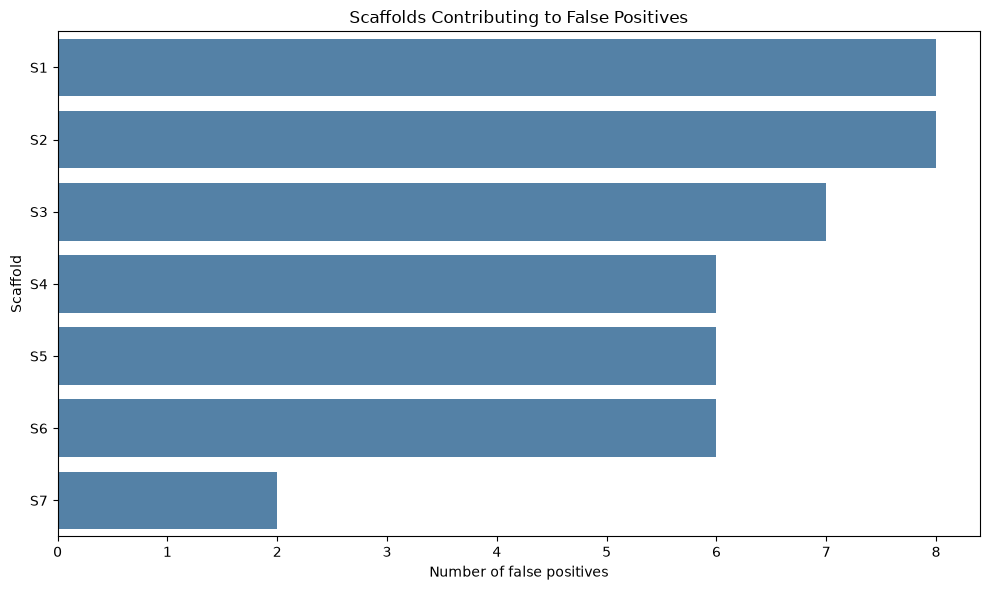

,Scaffold_ID,Test_Molecules,NonInhibitors,False_Positives,FP_Rate_among_NonInhibitors
0,S1,16,8,8,1.000
1,S2,55,14,8,0.571
2,S3,26,7,7,1.000
3,S4,26,6,6,1.000
4,S5,22,6,6,1.000
5,S6,53,26,6,0.231
6,S7,31,2,2,1.000


In [41]:
plot_errors = (
    scaffold_errors
    .head(15)
    .reset_index()
    .copy()
)

# Short identifiers for display
plot_errors["Scaffold_ID"] = [
    f"S{i+1}" for i in range(len(plot_errors))
]

plt.figure(figsize=(10, 6))

sns.barplot(
    data=plot_errors,
    x="False_Positives",
    y="Scaffold_ID",
    color="steelblue",
)

plt.xlabel("Number of false positives")
plt.ylabel("Scaffold")
plt.title("Scaffolds Contributing to False Positives")
plt.tight_layout()
plt.show()

display(
    plot_errors[
        [
            "Scaffold_ID",
            "Test_Molecules",
            "NonInhibitors",
            "False_Positives",
            "FP_Rate_among_NonInhibitors",
        ]
    ].round(3)
)

                    count   mean    std    min    25%    50%    75%    max
Prediction outcome                                                        
False positive       43.0  0.708  0.096  0.526  0.633  0.719  0.778  0.893
True negative        78.0  0.739  0.072  0.580  0.683  0.740  0.796  0.915


c:\Users\user\OneDrive\Desktop\GitHub\bace-alzheimers-classification\env\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


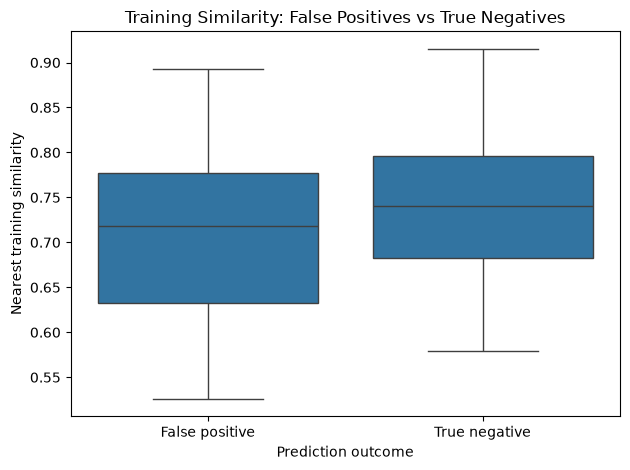

In [42]:
# Correctly classified non-inhibitors
tn_mask = (y[test_idx_scaffold] == 0) & (test_pred == 0)
tn_positions = test_idx_scaffold[tn_mask]

def nearest_train_similarity(indices):
    values = []

    for i in indices:
        sims = DataStructs.BulkTanimotoSimilarity(
            fingerprints[i], train_fps
        )
        values.append(max(sims))

    return np.asarray(values)

fp_similarity = nearest_train_similarity(fp_positions)
tn_similarity = nearest_train_similarity(tn_positions)

similarity_comparison = pd.DataFrame({
    "Nearest training similarity": np.concatenate(
        [fp_similarity, tn_similarity]
    ),
    "Prediction outcome": (
        ["False positive"] * len(fp_similarity)
        + ["True negative"] * len(tn_similarity)
    ),
})

print(
    similarity_comparison.groupby("Prediction outcome")[
        "Nearest training similarity"
    ].describe().round(3)
)

sns.boxplot(
    data=similarity_comparison,
    x="Prediction outcome",
    y="Nearest training similarity",
)
plt.title("Training Similarity: False Positives vs True Negatives")
plt.tight_layout()
plt.show()

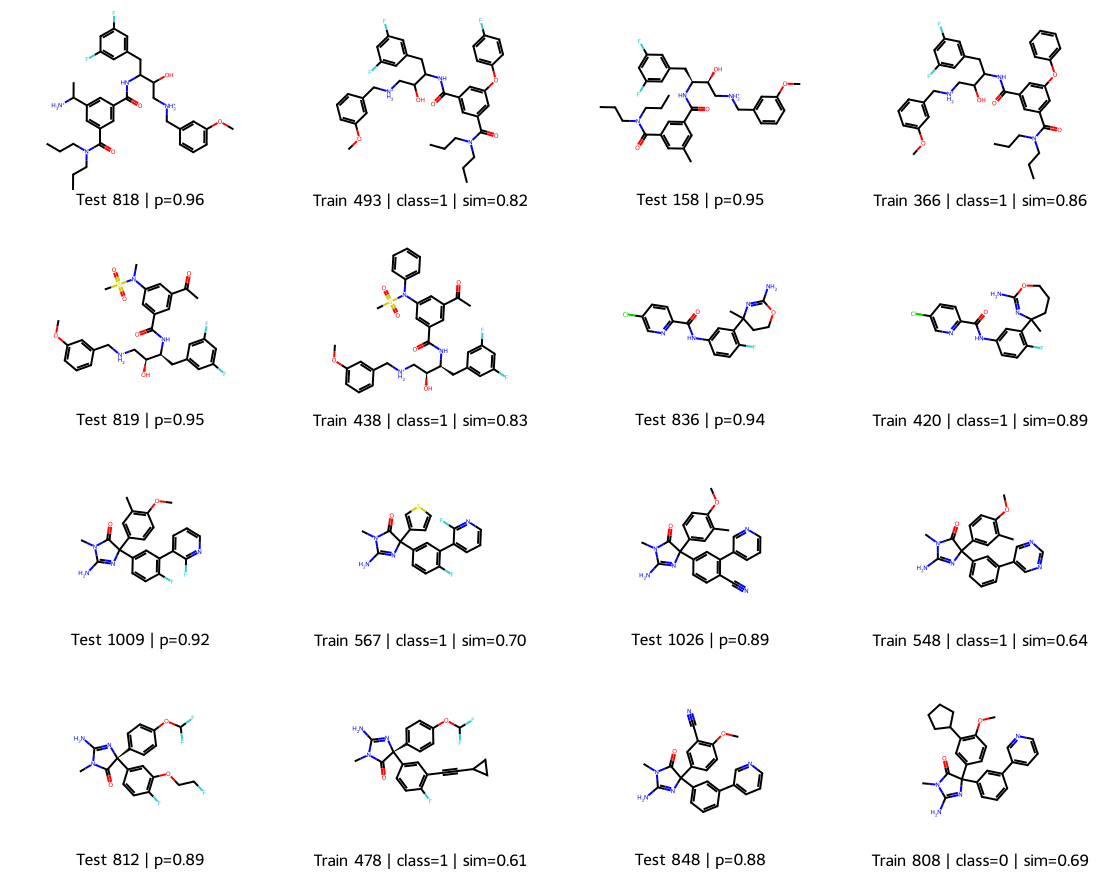

In [43]:
top_fp = false_positives.head(8)

mols = []
legends = []

for _, row in top_fp.iterrows():
    test_mol = Chem.MolFromSmiles(row["SMILES"])
    train_mol = Chem.MolFromSmiles(row["Nearest_Train_SMILES"])

    mols.extend([test_mol, train_mol])

    legends.extend([
        f"Test {row['Index']} | p={row['Predicted_Probability']:.2f}",
        f"Train {row['Nearest_Train_Index']} | "
        f"class={row['Nearest_Train_Class']} | "
        f"sim={row['Nearest_Tanimoto']:.2f}",
    ])

display(
    Draw.MolsToGridImage(
        mols,
        molsPerRow=4,
        subImgSize=(280, 220),
        legends=legends,
    )
)

In [44]:
# All actual non-inhibitors in the scaffold test set
non_inhibitors = test_scaffolds_df[
    test_scaffolds_df["Actual"] == 0
].copy()

print("Actual non-inhibitors:", len(non_inhibitors))

print("\nPrediction counts:")
print(non_inhibitors["Predicted"].value_counts().sort_index())

print("\nProbability ranges by predicted class:")
print(
    non_inhibitors.groupby("Predicted")["Probability"]
    .agg(["count", "mean", "min", "median", "max"])
    .round(3)
)

# Check consistency with the 0.5 threshold
print(
    "\nPredictions inconsistent with threshold:",
    (
        non_inhibitors["Predicted"]
        != (non_inhibitors["Probability"] >= 0.5).astype(int)
    ).sum()
)

Actual non-inhibitors: 121

Prediction counts:
Predicted
0    78
1    43
Name: count, dtype: int64

Probability ranges by predicted class:
           count   mean    min  median    max
Predicted                                    
0             78  0.155  0.002   0.150  0.494
1             43  0.767  0.508   0.778  0.960

Predictions inconsistent with threshold: 0


In [45]:
from statsmodels.stats.proportion import proportion_confint

non_inhibitors = test_scaffolds_df[
    test_scaffolds_df["Actual"] == 0
].copy()

scaffold_fp = (
    non_inhibitors.groupby("Scaffold")
    .agg(
        N=("Predicted", "size"),
        False_Positives=("Predicted", "sum"),
        Mean_Probability=("Probability", "mean"),
    )
    .reset_index()
)

scaffold_fp["FP_Rate"] = (
    scaffold_fp["False_Positives"] / scaffold_fp["N"]
)

intervals = scaffold_fp.apply(
    lambda r: proportion_confint(
        int(r["False_Positives"]),
        int(r["N"]),
        method="wilson",
    ),
    axis=1,
)

scaffold_fp["CI_Lower"] = [x[0] for x in intervals]
scaffold_fp["CI_Upper"] = [x[1] for x in intervals]

scaffold_fp = scaffold_fp.sort_values(
    ["FP_Rate", "N"], ascending=[False, False]
)

print(
    scaffold_fp[
        [
            "N", "False_Positives", "FP_Rate",
            "CI_Lower", "CI_Upper", "Mean_Probability"
        ]
    ].round(3).to_string()
)

    N  False_Positives  FP_Rate  CI_Lower  CI_Upper  Mean_Probability
0   8                8    1.000     0.676     1.000             0.724
1   7                7    1.000     0.646     1.000             0.836
2   6                6    1.000     0.610     1.000             0.814
3   6                6    1.000     0.610     1.000             0.811
9   2                2    1.000     0.342     1.000             0.785
4  14                8    0.571     0.326     0.786             0.572
6  26                6    0.231     0.110     0.421             0.315
8  28                0    0.000     0.000     0.121             0.148
7  17                0    0.000     0.000     0.184             0.050
5   7                0    0.000     0.000     0.354             0.130


In [46]:
from scipy.stats import chi2_contingency

eligible = scaffold_fp[scaffold_fp["N"] >= 5].copy()

contingency = np.column_stack([
    eligible["False_Positives"].to_numpy(),
    (eligible["N"] - eligible["False_Positives"]).to_numpy(),
])

chi2, p_value, dof, expected = chi2_contingency(contingency)

print("Scaffolds tested:", len(eligible))
print("Chi-square:", round(chi2, 3))
print("Degrees of freedom:", dof)
print("P-value:", p_value)
print("Minimum expected cell count:", round(expected.min(), 3))

Scaffolds tested: 9
Chi-square: 83.381
Degrees of freedom: 8
P-value: 1.0178191603553248e-14
Minimum expected cell count: 2.067


## Stratified Murko scaffold split

In [47]:
def stratified_scaffold_split(
    smiles,
    labels,
    train_size=0.8,
    test_size=0.2,
    random_state=42,
    size_weight=1.0,
    balance_weight=1.0,
    n_trials=500,
):
    """
    Greedy scaffold-group split optimized for molecule count and
    molecule-level class balance.

    All molecules sharing a Bemis-Murcko scaffold stay together.

    Supports binary classification with labels encoded as 0 and 1.

    Returns:
        train_idx, test_idx: original sample indices.
    """
    smiles = list(smiles)
    y = np.asarray(labels).reshape(-1)

    if len(smiles) != len(y):
        raise ValueError("smiles and labels must have equal lengths.")
    if not np.isin(y, [0, 1]).all():
        raise ValueError("labels must be binary and encoded as 0/1.")
    if not np.isclose(train_size + test_size, 1.0):
        raise ValueError("train_size and test_size must sum to 1.")
    if train_size <= 0 or test_size <= 0:
        raise ValueError("Both split sizes must be positive.")

    # Group molecules by Bemis-Murcko scaffold.
    scaffold_to_indices = defaultdict(list)

    for i, smi in enumerate(smiles):
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            raise ValueError(f"Invalid SMILES at index {i}: {smi}")

        scaffold = MurckoScaffold.MurckoScaffoldSmiles(
            mol=mol,
            includeChirality=False,
        )
        scaffold_to_indices[scaffold].append(i)

    groups = list(scaffold_to_indices.values())
    if len(groups) < 2:
        raise ValueError("At least two distinct scaffold groups are required.")

    # Each row contains [total molecules, positive molecules].
    group_stats = np.array([
        [len(idx), int(y[idx].sum())]
        for idx in groups
    ], dtype=float)

    n = len(y)
    total_positive = float(y.sum())
    total_negative = n - total_positive

    if total_positive == 0 or total_negative == 0:
        raise ValueError("Both classes must be present.")

    target_test_n = test_size * n
    target_test_pos = test_size * total_positive
    target_test_neg = test_size * total_negative

    rng = np.random.default_rng(random_state)
    best_test_groups = None
    best_score = np.inf

    # Repeated randomized greedy assignments; retain the best objective.
    for _ in range(n_trials):
        # Large groups first, with randomized tie-breaking.
        tie_break = rng.random(len(groups))
        order = sorted(
            range(len(groups)),
            key=lambda j: (
                group_stats[j, 0],
                tie_break[j],
            ),
            reverse=True,
        )

        test_group_ids = []
        current = np.zeros(2, dtype=float)  # total, positives

        for j in order:
            size, positives = group_stats[j]
            negatives = size - positives

            # Evaluate adding this group to test versus train.
            candidate = current + [size, positives]

            # Normalize errors so size and class balance contribute
            # on comparable scales.
            candidate_neg = candidate[0] - candidate[1]

            test_size_error = (
                (candidate[0] - target_test_n) / max(n, 1)
            ) ** 2

            test_pos_error = (
                (candidate[1] - target_test_pos)
                / max(total_positive, 1)
            ) ** 2

            test_neg_error = (
                (candidate_neg - target_test_neg)
                / max(total_negative, 1)
            ) ** 2

            # Also consider the assignment if this group stays in train.
            current_neg = current[0] - current[1]

            current_score = (
                size_weight * ((current[0] - target_test_n) / n) ** 2
                + balance_weight * (
                    ((current[1] - target_test_pos)
                     / total_positive) ** 2
                    + ((current_neg - target_test_neg)
                       / total_negative) ** 2
                )
            )

            candidate_score = (
                size_weight * test_size_error
                + balance_weight * (test_pos_error + test_neg_error)
            )

            # Greedy choice: add if it improves the objective.
            if candidate_score < current_score:
                current = candidate
                test_group_ids.append(j)

        # Ensure neither split is empty.
        if not test_group_ids or len(test_group_ids) == len(groups):
            continue

        test_indices = [
            i for j in test_group_ids for i in groups[j]
        ]
        test_y = y[test_indices]

        # Final objective uses actual molecule counts and class balance.
        n_test = len(test_indices)
        n_test_pos = int(test_y.sum())
        n_test_neg = n_test - n_test_pos

        score = (
            size_weight * ((n_test - target_test_n) / n) ** 2
            + balance_weight * (
                ((n_test_pos - target_test_pos)
                 / total_positive) ** 2
                + ((n_test_neg - target_test_neg)
                   / total_negative) ** 2
            )
        )

        if score < best_score:
            best_score = score
            best_test_groups = set(test_group_ids)

    if best_test_groups is None:
        raise ValueError(
            "Could not find a valid split. Try increasing n_trials."
        )

    test_idx = np.array(sorted(
        i for j in best_test_groups for i in groups[j]
    ), dtype=int)

    train_idx = np.array(sorted(
        i for j, group in enumerate(groups)
        if j not in best_test_groups
        for i in group
    ), dtype=int)

    return train_idx, test_idx

In [48]:
train_idx_arithmetic, test_idx_arithmetic = stratified_scaffold_split(
    smiles=df['mol'],
    labels=y,
    train_size=0.8,
    test_size=0.2,
    random_state=42,
    n_trials=2000,
)

results = pd.DataFrame({
    "Random split": evaluate_split(
        X_fp, y, random_train, random_test
    ),
    "Scaffold split": evaluate_split(
        X_fp, y, train_idx_scaffold, test_idx_scaffold
    ),
    "Stratified scaffold split": evaluate_split(
        X_fp, y, train_idx_arithmetic, test_idx_arithmetic
    ),
}).T

print(results.round(3))

                           ROC-AUC  PR-AUC  Balanced accuracy
Random split                 0.884   0.858              0.789
Scaffold split               0.838   0.884              0.741
Stratified scaffold split    0.880   0.880              0.806


In [49]:
y = np.asarray(y)

for name, train_idx, test_idx in [
    ("Random", random_train, random_test),
    ("Scaffold", train_idx_scaffold, test_idx_scaffold),
    ("Stratified scaffold", train_idx_arithmetic, test_idx_arithmetic),
]:
    print(f"\n{name}")
    print(f"Train size: {len(train_idx)}")
    print(f"Test size:  {len(test_idx)}")
    print(f"Train positive rate: {y[train_idx].mean():.3f}")
    print(f"Test positive rate:  {y[test_idx].mean():.3f}")


Random
Train size: 1210
Test size:  303
Train positive rate: 0.457
Test positive rate:  0.455

Scaffold
Train size: 1207
Test size:  306
Train positive rate: 0.419
Test positive rate:  0.605

Stratified scaffold
Train size: 1180
Test size:  333
Train positive rate: 0.435
Test positive rate:  0.535


In [50]:
for name, idx in [
    ("Train", train_idx_arithmetic),
    ("Test", test_idx_arithmetic),
]:
    print(
        f"{name}: n={len(idx)}, "
        f"positive_rate={y[idx].mean():.3f}"
    )

print(
    "Total assigned:",
    len(train_idx_arithmetic) + len(test_idx_arithmetic),
    "of",
    len(y),
)

Train: n=1180, positive_rate=0.435
Test: n=333, positive_rate=0.535
Total assigned: 1513 of 1513


In [51]:
def scaffold_set(indices):
    return {
        MurckoScaffold.MurckoScaffoldSmiles(
            mol=Chem.MolFromSmiles(df['mol'][i]),
            includeChirality=False,
        )
        for i in indices
    }

train_scaffolds = scaffold_set(train_idx_arithmetic)
test_scaffolds = scaffold_set(test_idx_arithmetic)

print("Shared scaffolds:", len(train_scaffolds & test_scaffolds))

Shared scaffolds: 0


RANDOM SPLIT
               precision    recall  f1-score   support

Non-Inhibitor      0.818     0.788     0.802       165
    Inhibitor      0.757     0.790     0.773       138

     accuracy                          0.789       303
    macro avg      0.787     0.789     0.788       303
 weighted avg      0.790     0.789     0.789       303

Confusion matrix:
[[130  35]
 [ 29 109]]


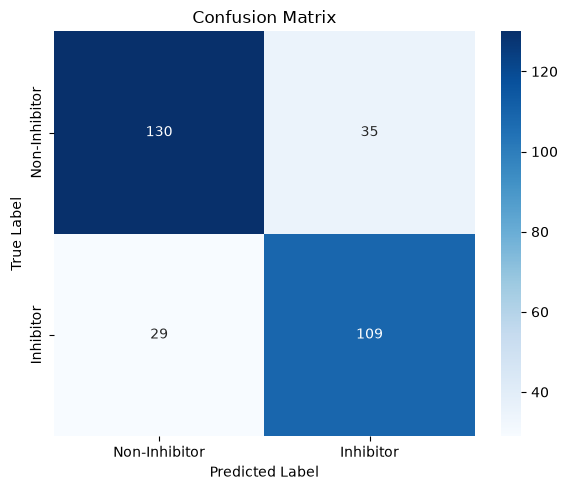


SCAFFOLD SPLIT
               precision    recall  f1-score   support

Non-Inhibitor      0.722     0.645     0.681       121
    Inhibitor      0.783     0.838     0.809       185

     accuracy                          0.761       306
    macro avg      0.753     0.741     0.745       306
 weighted avg      0.759     0.761     0.759       306

Confusion matrix:
[[ 78  43]
 [ 30 155]]


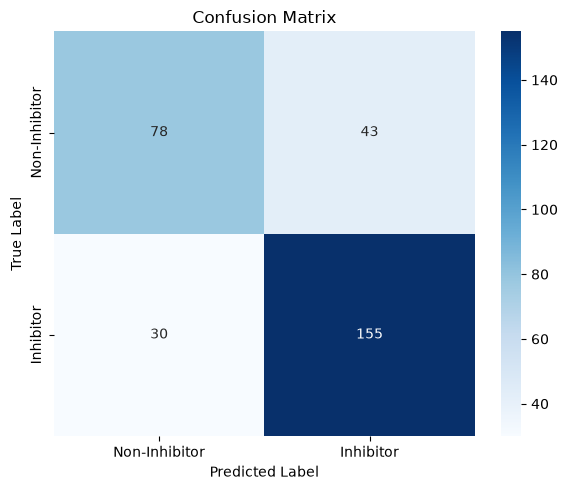


STRATIFIED SCAFFOLD SPLIT
               precision    recall  f1-score   support

Non-Inhibitor      0.805     0.774     0.789       155
    Inhibitor      0.810     0.837     0.823       178

     accuracy                          0.808       333
    macro avg      0.808     0.806     0.806       333
 weighted avg      0.808     0.808     0.808       333

Confusion matrix:
[[120  35]
 [ 29 149]]


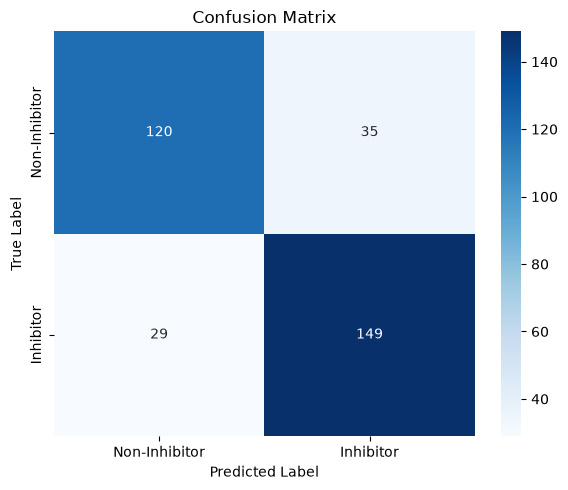

In [52]:
print("RANDOM SPLIT")
detailed_evaluation(X_fp, y, random_train, random_test)

print("\nSCAFFOLD SPLIT")
detailed_evaluation(
    X_fp, y, train_idx_scaffold, test_idx_scaffold
)

print("\nSTRATIFIED SCAFFOLD SPLIT")
detailed_evaluation(
    X_fp, y, train_idx_arithmetic, test_idx_arithmetic
)

c:\Users\user\OneDrive\Desktop\GitHub\bace-alzheimers-classification\env\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\Users\user\OneDrive\Desktop\GitHub\bace-alzheimers-classification\env\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\Users\user\OneDrive\Desktop\GitHub\bace-alzheimers-classification\env\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\Users\user\OneDrive\Desktop\GitHub\bace-alzheimers-classification\e

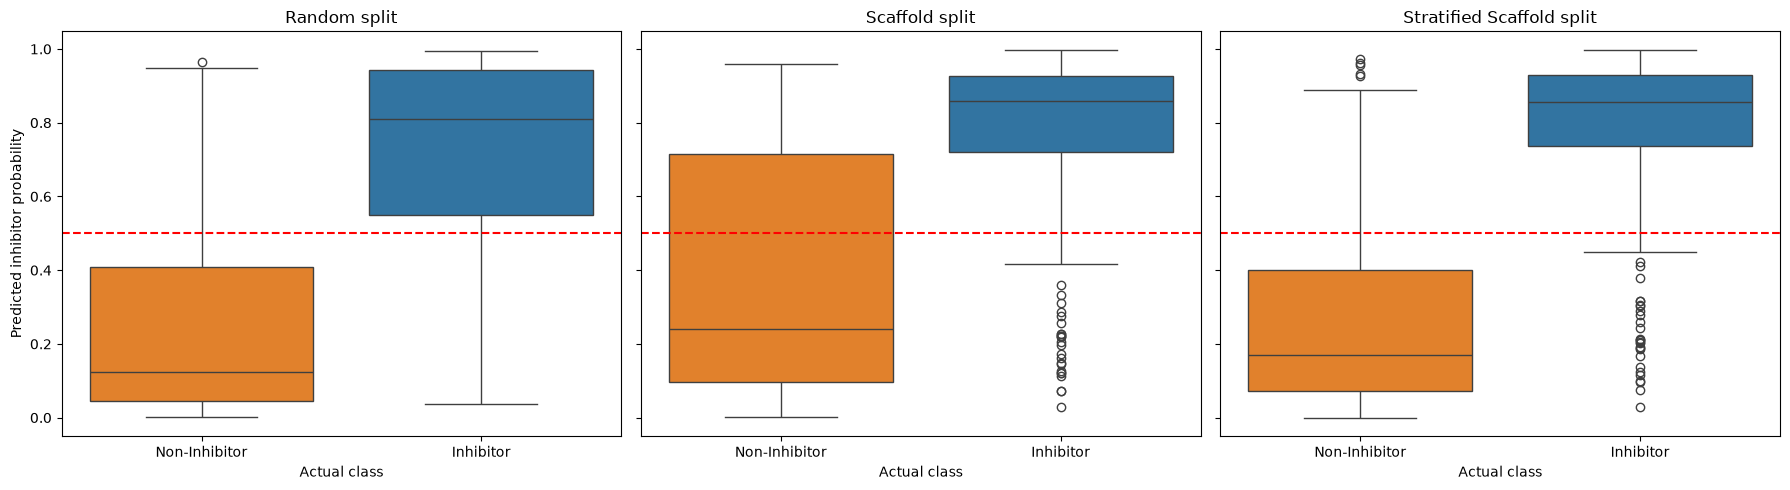

In [53]:

prob_df = pd.concat([
    get_predictions(X_fp, y, random_train, random_test, "Random"),
    get_predictions(
        X_fp, y, train_idx_scaffold, test_idx_scaffold, "Scaffold"
    ),
    get_predictions(
        X_fp, y, train_idx_arithmetic, test_idx_arithmetic, "Stratified Scaffold"
    ),
], ignore_index=True)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, split_name in zip(axes, ["Random", "Scaffold", "Stratified Scaffold"]):
    subset = prob_df[prob_df["Split"] == split_name]

    sns.boxplot(
        data=subset,
        x="Actual class",
        y="Predicted inhibitor probability",
        hue="Actual class",
        order=["Non-Inhibitor", "Inhibitor"],
        legend=False,
        ax=ax,
    )

    ax.axhline(0.5, color="red", linestyle="--")
    ax.set_title(f"{split_name} split")
    ax.set_xlabel("Actual class")

plt.tight_layout()
plt.show()

In [54]:
from sklearn.base import clone


y_array = np.asarray(y).ravel()
X = np.asarray(X_fp)

seeds = range(20)
records = []

for seed in seeds:
    
    estimator = RandomForestClassifier(
                n_estimators=500,
                class_weight="balanced",
                random_state=seed,
                n_jobs=-1
            )
    
    # Generate a new scaffold split for this seed.
    train_idx, test_idx = stratified_scaffold_split(
        smiles=df["mol"],
        labels=y_array,
        train_size=0.8,
        test_size=0.2,
        random_state=seed,
        n_trials=2000,
    )

    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y_array[train_idx], y_array[test_idx]

    # Fit a fresh model for each split.
    clf = clone(estimator)
    clf.fit(X_train, y_train)

    # Continuous scores for ranking metrics.
    if hasattr(clf, "predict_proba"):
        scores = clf.predict_proba(X_test)[:, 1]
    elif hasattr(clf, "decision_function"):
        scores = clf.decision_function(X_test)
    else:
        raise ValueError(
            "The estimator needs predict_proba or decision_function "
            "to calculate ROC-AUC and PR-AUC."
        )

    # Keep the classification threshold fixed across all seeds.
    predictions = (scores >= 0.5).astype(int)

    records.append({
        "seed": seed,
        "ROC-AUC": roc_auc_score(y_test, scores),
        "PR-AUC": average_precision_score(y_test, scores),
        "Balanced accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "Inhibitor F1": f1_score(
            y_test, predictions, pos_label=1
        ),
        "train_size": len(train_idx),
        "test_size": len(test_idx),
        "test_positive_rate": y_test.mean(),
    })

results_seeds = pd.DataFrame(records)

# Report mean and sample standard deviation across seeds.
metrics = [
    "ROC-AUC",
    "PR-AUC",
    "Balanced accuracy",
    "Inhibitor F1",
]

summary = pd.DataFrame({
    "Mean": results_seeds[metrics].mean(),
    "Std": results_seeds[metrics].std(ddof=1),
})

summary["Mean ± SD"] = summary.apply(
    lambda row: f"{row['Mean']:.3f} ± {row['Std']:.3f}",
    axis=1,
)

print("Performance across 20 scaffold splits")
print(summary[["Mean ± SD"]])

print("\nPer-seed results:")
print(results_seeds[["seed"] + metrics].round(3).to_string(index=False))

print("\nSplit diagnostics:")
print(
    results_seeds[
        ["train_size", "test_size", "test_positive_rate"]
    ].agg(["mean", "std", "min", "max"]).round(3)
)

Performance across 20 scaffold splits
                       Mean ± SD
ROC-AUC            0.879 ± 0.002
PR-AUC             0.882 ± 0.004
Balanced accuracy  0.803 ± 0.003
Inhibitor F1       0.820 ± 0.003

Per-seed results:
 seed  ROC-AUC  PR-AUC  Balanced accuracy  Inhibitor F1
    0    0.883   0.885              0.809         0.825
    1    0.880   0.883              0.806         0.823
    2    0.882   0.886              0.806         0.823
    3    0.882   0.887              0.803         0.820
    4    0.883   0.889              0.802         0.821
    5    0.879   0.881              0.797         0.813
    6    0.878   0.880              0.803         0.819
    7    0.878   0.883              0.809         0.825
    8    0.878   0.882              0.800         0.818
    9    0.879   0.881              0.803         0.819
   10    0.880   0.878              0.800         0.817
   11    0.879   0.880              0.797         0.814
   12    0.882   0.886              0.800         

In [55]:
df[["mol", "Class"]].to_csv("../data/MoleculeNet/bace/raw/bace_processed.csv", index=False)